# Быстрый старт с stt-ru

[![Open in Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/SergeyShk/Speech-to-Text-Russian/blob/master/notebooks/01_quickstart.ipynb)

Стереозапись телефонного разговора от чтения файла до результата: распознавание моделью GigaAM-v3, фрагменты по говорящим, форма волны, форматы результата, сведение каналов и та же работа командой `stt-ru`.

## Установка

В Colab ячейка ставит stt-ru и `pandas`, `matplotlib`; в окружении, где пакет уже есть, ничего не делает.

In [1]:
import importlib.util
import subprocess
import sys

if importlib.util.find_spec("stt_ru") is None:
    subprocess.run(
        [sys.executable, "-m", "pip", "install", "-q", "stt-ru[ffmpeg]", "pandas", "matplotlib"],
        check=True,
    )

## Запись

Звонок в колл-центр длиной 16 секунд из тестов проекта: в канале 1 - оператор, в канале 0 - клиент. Вместо него можно подставить свою запись в `CALL`.

In [2]:
import urllib.request
from pathlib import Path

DATA = Path("data")
DATA.mkdir(exist_ok=True)
CALL = DATA / "call.wav"
if not CALL.exists():
    urllib.request.urlretrieve(
        "https://raw.githubusercontent.com/SergeyShk/Speech-to-Text-Russian/master/tests/data/call.wav",
        CALL,
    )

In [3]:
import IPython.display as ipd
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import soundfile as sf

from stt_ru import Transcriber
from stt_ru.audio import Audio, load_audio
from stt_ru.export import FORMATS, render

pd.set_option("display.max_colwidth", None)


def listen(samples, sample_rate, name):
    # MP3 в несколько раз меньше WAV: звук плеера сохраняется в ноутбуке
    path = DATA / f"{name}.mp3"
    sf.write(path, samples, sample_rate)
    return ipd.Audio(filename=path)


audio = load_audio(CALL)
print(
    f"Каналов: {audio.num_channels}, частота: {audio.sample_rate} Гц, длительность: {audio.duration:.1f} с"
)

Каналов: 2, частота: 8000 Гц, длительность: 15.8 с


В плеере канал 0 (клиент) слышен слева, канал 1 (оператор) - справа.

In [4]:
listen(audio.samples, audio.sample_rate, "call")

## Распознавание

`Transcriber` загружает модель один раз: при первом запуске она скачивается с Hugging Face (около 230 МБ), потом берется из кэша. Каналы стереозаписи распознаются отдельно, у каждого фрагмента есть начало, конец, канал и текст.

In [5]:
transcriber = Transcriber()
result = transcriber.transcribe(CALL)
print(f"Модель: {result.model}, каналов: {result.channels}, фрагментов: {len(result.segments)}")

Модель: gigaam-v3-e2e-rnnt, каналов: 2, фрагментов: 5


In [6]:
segments = pd.DataFrame(
    [
        {"Начало, с": s.start, "Конец, с": s.end, "Говорящий": s.speaker, "Текст": s.text}
        for s in result.segments
    ]
)
segments

,"Начало, с","Конец, с",Говорящий,Текст
0,0.994,9.054,Канал 1,"Наталья, благодарю вас за ожидание. По данному вопросу я сейчас ваш звонок переведу на специалиста профильного подразделения. Оставайтесь, пожалуйста, на линии."
1,3.490,3.934,Канал 0,Угу
2,7.682,8.222,Канал 0,Угу
3,9.634,12.638,Канал 1,"Я в свою очередь с вами прощаюсь. Всего доброго, до свидания."
4,12.994,13.662,Канал 0,До свидания.


Фрагменты идут по времени начала, поэтому короткие «Угу» клиента стоят между репликами оператора: клиент поддакивает, пока оператор говорит. Текст всей записи - `result.text`.

In [7]:
result.text

'Наталья, благодарю вас за ожидание. По данному вопросу я сейчас ваш звонок переведу на специалиста профильного подразделения. Оставайтесь, пожалуйста, на линии. Угу Угу Я в свою очередь с вами прощаюсь. Всего доброго, до свидания. До свидания.'

Фрагмент можно вырезать из записи по началу, концу и каналу и послушать, например последнюю реплику оператора. Если канала у фрагмента нет (`None`: монозапись или одинаковые каналы), берется канал 0:

In [8]:
segment = [s for s in result.segments if s.channel in (1, None)][-1]
start, end = (round(seconds * audio.sample_rate) for seconds in (segment.start, segment.end))
listen(audio.samples[start:end, segment.channel or 0], audio.sample_rate, "segment")

## Форма волны

`Audio.peaks` дает пики амплитуды для рисования формы волны. Подсвечены фрагменты, которые нашел поиск речи: так видно, где каждый говорящий говорит.

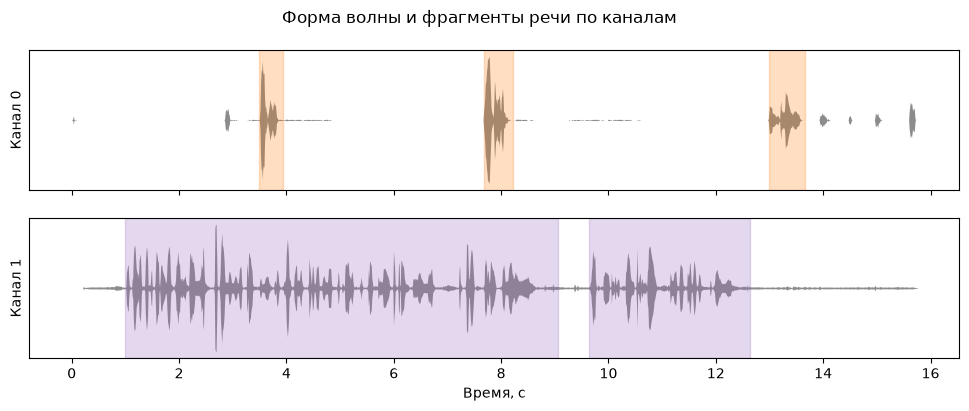

In [9]:
peaks = audio.peaks(1500)
seconds = np.linspace(0, audio.duration, peaks.shape[1])
colors = {0: "tab:orange", 1: "tab:purple"}

fig, axes = plt.subplots(audio.num_channels, 1, figsize=(12, 4), sharex=True)
for channel, ax in enumerate(axes):
    ax.fill_between(seconds, -peaks[channel], peaks[channel], color="0.55", linewidth=0)
    for segment in result.segments:
        if segment.channel == channel:
            ax.axvspan(segment.start, segment.end, color=colors[channel], alpha=0.25)
    ax.set_ylabel(f"Канал {channel}")
    ax.set_yticks([])
axes[-1].set_xlabel("Время, с")
fig.suptitle("Форма волны и фрагменты речи по каналам")
plt.show()

## Форматы результата

`save` выбирает формат по расширению файла, `render` возвращает текст в формате. Форматы - для чтения (TXT), программ (JSON, JSONL), субтитров (SRT, VTT, ASS для Aegisub) и таблиц (CSV).

In [10]:
for fmt in FORMATS:
    path = result.save(DATA / f"call.{fmt}")
    print(f"{path.name:10} {path.stat().st_size:>5} байт")

call.txt     512 байт
call.json   1183 байт
call.jsonl   969 байт
call.srt     677 байт
call.vtt     755 байт
call.ass    1465 байт
call.csv     642 байт


In [11]:
print(render(result, "srt"))

1
00:00:00,994 --> 00:00:09,054
Канал 1: Наталья, благодарю вас за ожидание. По данному вопросу я сейчас ваш звонок переведу на специалиста профильного подразделения. Оставайтесь, пожалуйста, на линии.

2
00:00:03,490 --> 00:00:03,934
Канал 0: Угу

3
00:00:07,682 --> 00:00:08,222
Канал 0: Угу

4
00:00:09,634 --> 00:00:12,638
Канал 1: Я в свою очередь с вами прощаюсь. Всего доброго, до свидания.

5
00:00:12,994 --> 00:00:13,662
Канал 0: До свидания.




CSV с колонками версии 0.2 и временем в миллисекундах - для Excel и аналитики:

In [12]:
print(render(result, "csv"))

Audio File,Start,End,Name,Text
call.wav,994,9054,Канал 1,"Наталья, благодарю вас за ожидание. По данному вопросу я сейчас ваш звонок переведу на специалиста профильного подразделения. Оставайтесь, пожалуйста, на линии."
call.wav,3490,3934,Канал 0,Угу
call.wav,7682,8222,Канал 0,Угу
call.wav,9634,12638,Канал 1,"Я в свою очередь с вами прощаюсь. Всего доброго, до свидания."
call.wav,12994,13662,Канал 0,До свидания.



## Сведение каналов

Если каналы - не разные говорящие (например, стереозапись лекции), их сводят в один: `split_channels=False` в Python или `--mono` в команде. Говорящего тогда нет, а одновременная речь попадает в один фрагмент: короткие тихие реплики поверх чужой речи могут пропасть, как «Угу» клиента здесь.

In [13]:
mono = Transcriber(split_channels=False).transcribe(CALL)
pd.DataFrame([{"Начало, с": s.start, "Конец, с": s.end, "Текст": s.text} for s in mono.segments])

,"Начало, с","Конец, с",Текст
0,0.994,8.894,"Наталья, благодарю вас за ожидание. По данному вопросу я сейчас ваш звонок переведу на специалиста профильного подразделения. Оставайтесь, пожалуйста, на линии."
1,9.634,12.638,"Я в свою очередь с вами прощаюсь. Всего доброго, до свидания."
2,12.962,13.726,До свидания.


## Запись в памяти

`transcribe_audio` распознает запись, которая уже в памяти: например, только канал оператора.

In [14]:
operator = Audio(audio.samples[:, 1:2], audio.sample_rate)
transcriber.transcribe_audio(operator, source="оператор").text

'Наталья, благодарю вас за ожидание. По данному вопросу я сейчас ваш звонок переведу на специалиста профильного подразделения. Оставайтесь, пожалуйста, на линии. Я в свою очередь с вами прощаюсь. Всего доброго, до свидания.'

## Команда stt-ru

Все то же из командной строки: без `-o` результат печатается, с `-o` сохраняется в каталог в выбранных форматах.

In [15]:
%%bash
stt-ru transcribe data/call.wav -q

Канал 1: Наталья, благодарю вас за ожидание. По данному вопросу я сейчас ваш звонок переведу на специалиста профильного подразделения. Оставайтесь, пожалуйста, на линии.
Канал 0: Угу
Канал 0: Угу
Канал 1: Я в свою очередь с вами прощаюсь. Всего доброго, до свидания.
Канал 0: До свидания.


In [16]:
%%bash
stt-ru transcribe data/call.wav -o data/out -f srt,csv -q
ls data/out

call.csv
call.srt


## Дальше

* [02_call_analytics.ipynb](02_call_analytics.ipynb) - аналитика звонка: доля речи, паузы, реакция, поиск фраз, пакетная обработка
* [03_long_recording.ipynb](03_long_recording.ipynb) - длинная запись и субтитры
* [04_model_evaluation.ipynb](04_model_evaluation.ipynb) - оценка моделей на своей разметке
* [05_web_service.ipynb](05_web_service.ipynb) - веб-сервис и REST API из Python
* [Документация](https://sergeyshk.github.io/Speech-to-Text-Russian/)